# Adaptive RAG: LangGraph + Cohere chat + HuggingFace embeddings + Chroma + Tavily

Implements the architecture from the lecture diagram:

- **Query analysis**: an LLM router picks one of three routes
  - `vectorstore`: topics covered by the index (agents, prompt engineering, adversarial attacks)
  - `web_search`: current events
  - `llm_fallback`: anything else, answered directly by the LLM
- **RAG + self-reflection** on the retrieval path
  1. Retrieve, then grade each document for relevance
  2. If nothing is relevant: rewrite the query, then web search
  3. Generate an answer
  4. Hallucination check: if not grounded, regenerate (capped)
  5. Answer check: if it doesn't address the question, rewrite the query and web search (capped)

Embeddings run locally (no key needed). You need `COHERE_API_KEY` (chat model) and `TAVILY_API_KEY` (web search).

## 1. Install
Run once, then **restart the kernel** before continuing.

In [ ]:
%pip install -q langchain langchain-core langchain-community langchain-cohere langchain-chroma langchain-huggingface langchain-text-splitters langchain-tavily langgraph chromadb sentence-transformers beautifulsoup4 tiktoken python-dotenv "pydantic>=2"

## 2. API keys
Reads from a `.env` file or environment variables, and prompts for anything missing.

In [8]:
import os
from getpass import getpass
from dotenv import load_dotenv

load_dotenv()

for key in ["COHERE_API_KEY", "TAVILY_API_KEY"]:
    if not os.getenv(key):
        os.environ[key] = getpass(f"{key}: ")

# Optional: LangSmith tracing to inspect every node and grader decision
# os.environ["LANGCHAIN_TRACING_V2"] = "true"
# os.environ["LANGCHAIN_API_KEY"] = "..."
# os.environ["LANGCHAIN_PROJECT"] = "adaptive-rag"

# Optional model overrides
COHERE_MODEL = os.getenv("COHERE_MODEL", "command-a-03-2025")
EMBEDDING_MODEL = os.getenv("EMBEDDING_MODEL", "sentence-transformers/all-MiniLM-L6-v2")

## 3. Build the index
Loads the pages, chunks them, embeds locally with HuggingFace, and stores them in Chroma.
Set `REBUILD = True` if you change `URLS` or the embedding model.

In [9]:
import shutil
from langchain_chroma import Chroma
from langchain_community.document_loaders import WebBaseLoader
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

PERSIST_DIR = "./chroma_db"
COLLECTION = "adaptive-rag"
REBUILD = False

# The index is "about" these topics; the router prompt below describes the same topics.
URLS = [
    "https://lilianweng.github.io/posts/2023-06-23-agent/",
    "https://lilianweng.github.io/posts/2023-03-15-prompt-engineering/",
    "https://lilianweng.github.io/posts/2023-10-25-adv-attack-llm/",
]

embeddings = HuggingFaceEmbeddings(model_name=EMBEDDING_MODEL)

if REBUILD and os.path.exists(PERSIST_DIR):
    shutil.rmtree(PERSIST_DIR)

if not os.path.exists(PERSIST_DIR):
    docs = [d for url in URLS for d in WebBaseLoader(url).load()]
    splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(chunk_size=512, chunk_overlap=0)
    chunks = splitter.split_documents(docs)
    print(f"Loaded {len(docs)} pages -> {len(chunks)} chunks")
    vectorstore = Chroma.from_documents(
        chunks, embeddings, collection_name=COLLECTION, persist_directory=PERSIST_DIR
    )
else:
    print("Loading existing index")
    vectorstore = Chroma(
        collection_name=COLLECTION, embedding_function=embeddings, persist_directory=PERSIST_DIR
    )

retriever = vectorstore.as_retriever(search_kwargs={"k": 4})

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2673.07it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading existing index


## 4. Chains
| Component | Role in the diagram |
|---|---|
| `question_router` | Query Analysis |
| `retrieval_grader` | "Relevant to question?" |
| `rag_chain` | Generate |
| `hallucination_grader` | "Hallucinations?" |
| `answer_grader` | "Answers question?" |
| `question_rewriter` | Improves the query before web search |
| `llm_fallback_chain` | "anything else" branch |

In [15]:
from typing import Literal
from pydantic import BaseModel, Field
from langchain_cohere import ChatCohere
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

from langchain_core.rate_limiters import InMemoryRateLimiter

# ~15 calls/minute, safely under the trial limit of 20
rate_limiter = InMemoryRateLimiter(
    requests_per_second=0.25,
    check_every_n_seconds=0.1,
    max_bucket_size=1,
)

llm = ChatCohere(model=COHERE_MODEL, temperature=0, rate_limiter=rate_limiter)


# ---- 1. Router -------------------------------------------------------------
class RouteQuery(BaseModel):
    """Route a user question to the most relevant data source."""
    datasource: Literal["vectorstore", "web_search", "llm_fallback"] = Field(
        description=(
            "vectorstore for LLM agents, prompt engineering and adversarial attacks on LLMs; "
            "web_search for current events or recent info; "
            "llm_fallback for anything else (chit-chat, general knowledge)."
        )
    )

router_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are an expert at routing a user question.\n"
     "- The vectorstore contains documents about LLM agents, prompt engineering, and "
     "adversarial attacks on LLMs. Use it for those topics.\n"
     "- Use web_search for questions about current events or anything needing up-to-date information.\n"
     "- Otherwise use llm_fallback."),
    ("human", "{question}"),
])
question_router = router_prompt | llm.with_structured_output(RouteQuery)


# ---- 2. Retrieval grader ---------------------------------------------------
class GradeDocuments(BaseModel):
    """Binary relevance check on a retrieved document."""
    binary_score: Literal["yes", "no"] = Field(
        description="Is the document relevant to the question? 'yes' or 'no'"
    )

retrieval_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a grader assessing the relevance of a retrieved document to a user question. "
     "If the document contains keywords or semantic meaning related to the question, grade it "
     "as relevant. This is a lenient check meant only to filter out clearly erroneous "
     "retrievals. Answer 'yes' or 'no'."),
    ("human", "Document:\n\n{document}\n\nQuestion: {question}"),
])
retrieval_grader = retrieval_prompt | llm.with_structured_output(GradeDocuments)


# ---- 3. RAG generation -----------------------------------------------------
rag_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are an assistant for question-answering tasks. Use ONLY the retrieved context below "
     "to answer. If the context does not contain the answer, say you don't know. "
     "Use at most three sentences."),
    ("human", "Question: {question}\n\nContext:\n{context}"),
])
rag_chain = rag_prompt | llm | StrOutputParser()


# ---- 4. Hallucination grader ----------------------------------------------
class GradeHallucinations(BaseModel):
    """Is the generation grounded in the provided facts?"""
    binary_score: Literal["yes", "no"] = Field(
        description="Answer is grounded in the facts: 'yes' or 'no'"
    )

hallucination_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a grader assessing whether an LLM generation is grounded in / supported by a set "
     "of retrieved facts. Answer 'yes' if it is grounded, 'no' if it contains unsupported claims."),
    ("human", "Facts:\n\n{documents}\n\nLLM generation: {generation}"),
])
hallucination_grader = hallucination_prompt | llm.with_structured_output(GradeHallucinations)


# ---- 5. Answer grader ------------------------------------------------------
class GradeAnswer(BaseModel):
    """Does the answer resolve the question?"""
    binary_score: Literal["yes", "no"] = Field(
        description="Answer addresses the question: 'yes' or 'no'"
    )

answer_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a grader assessing whether an answer addresses / resolves a question. "
     "Answer 'yes' or 'no'."),
    ("human", "Question: {question}\n\nAnswer: {generation}"),
])
answer_grader = answer_prompt | llm.with_structured_output(GradeAnswer)


# ---- 6. Question rewriter --------------------------------------------------
rewrite_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You rewrite input questions into a better version optimized for web search. "
     "Reason about the underlying semantic intent. Return ONLY the rewritten question."),
    ("human", "Initial question: {question}\n\nImproved question:"),
])
question_rewriter = rewrite_prompt | llm | StrOutputParser()


# ---- 7. LLM-only fallback --------------------------------------------------
fallback_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a helpful assistant. Answer concisely."),
    ("human", "{question}"),
])
llm_fallback_chain = fallback_prompt | llm | StrOutputParser()

## 5. Graph
```
question -> [query analysis]
  vectorstore   -> retrieve -> grade docs --(none relevant)--> rewrite query -> web search -> generate
                                   |(relevant)                                                 ^
                                   +------------------------------------------------------------+
  web_search    -> web search -> generate
  llm_fallback  -> answer with LLM -> END

generate -> hallucination check --(not grounded)--> generate (retry)
         -> answers question?   --(no)-------------> rewrite query -> web search -> generate
                                --(yes)------------> END
```

In [11]:
from typing import List, TypedDict
from langchain_core.documents import Document
from langchain_tavily import TavilySearch
from langgraph.graph import END, START, StateGraph

MAX_GENERATIONS = 3  # hallucination retries
MAX_REWRITES = 2     # query rewrite -> web search loops

web_search_tool = TavilySearch(max_results=3)


class GraphState(TypedDict, total=False):
    question: str
    generation: str
    documents: List[Document]
    generations: int  # times we've generated
    rewrites: int     # times we've rewritten the query


# ---- Nodes -----------------------------------------------------------------
def retrieve(state: GraphState) -> GraphState:
    return {"documents": retriever.invoke(state["question"])}


def grade_documents(state: GraphState) -> GraphState:
    kept = []
    for d in state["documents"]:
        score = retrieval_grader.invoke({"question": state["question"], "document": d.page_content})
        if score.binary_score == "yes":
            kept.append(d)
    print(f"   kept {len(kept)}/{len(state['documents'])} documents")
    return {"documents": kept}


def transform_query(state: GraphState) -> GraphState:
    better = question_rewriter.invoke({"question": state["question"]})
    print(f"   rewritten query: {better}")
    return {"question": better, "rewrites": state.get("rewrites", 0) + 1}


def web_search(state: GraphState) -> GraphState:
    result = web_search_tool.invoke({"query": state["question"]})
    hits = result["results"] if isinstance(result, dict) else result
    docs = [Document(page_content=h["content"], metadata={"source": h.get("url")}) for h in hits]
    return {"documents": docs}


def generate(state: GraphState) -> GraphState:
    context = "\n\n".join(d.page_content for d in state["documents"])
    answer = rag_chain.invoke({"question": state["question"], "context": context})
    return {"generation": answer, "generations": state.get("generations", 0) + 1}


def llm_fallback(state: GraphState) -> GraphState:
    return {"generation": llm_fallback_chain.invoke({"question": state["question"]})}


# ---- Conditional edges -----------------------------------------------------
def route_question(state: GraphState) -> str:
    route = question_router.invoke({"question": state["question"]})
    print(f"---ROUTE: {route.datasource}---")
    return route.datasource


def decide_after_grading(state: GraphState) -> str:
    if not state["documents"]:
        print("---NO RELEVANT DOCS -> rewrite + web search---")
        return "transform_query"
    return "generate"


def grade_generation(state: GraphState) -> str:
    docs_text = "\n\n".join(d.page_content for d in state["documents"])

    grounded = hallucination_grader.invoke(
        {"documents": docs_text, "generation": state["generation"]}
    )
    if grounded.binary_score == "no":
        if state.get("generations", 0) >= MAX_GENERATIONS:
            print("---STILL HALLUCINATING, MAX RETRIES -> giving up---")
            return "end"
        print("---NOT GROUNDED -> regenerate---")
        return "generate"

    useful = answer_grader.invoke(
        {"question": state["question"], "generation": state["generation"]}
    )
    if useful.binary_score == "yes":
        print("---GROUNDED + ANSWERS QUESTION---")
        return "end"

    if state.get("rewrites", 0) >= MAX_REWRITES:
        print("---ANSWER NOT USEFUL, MAX REWRITES -> giving up---")
        return "end"
    print("---GROUNDED BUT DOESN'T ANSWER -> rewrite + web search---")
    return "transform_query"


# ---- Wire it up ------------------------------------------------------------
g = StateGraph(GraphState)
g.add_node("retrieve", retrieve)
g.add_node("grade_documents", grade_documents)
g.add_node("transform_query", transform_query)
g.add_node("web_search", web_search)
g.add_node("generate", generate)
g.add_node("llm_fallback", llm_fallback)

g.add_conditional_edges(
    START, route_question,
    {"vectorstore": "retrieve", "web_search": "web_search", "llm_fallback": "llm_fallback"},
)
g.add_edge("retrieve", "grade_documents")
g.add_conditional_edges(
    "grade_documents", decide_after_grading,
    {"transform_query": "transform_query", "generate": "generate"},
)
g.add_edge("transform_query", "web_search")
g.add_edge("web_search", "generate")
g.add_conditional_edges(
    "generate", grade_generation,
    {"generate": "generate", "transform_query": "transform_query", "end": END},
)
g.add_edge("llm_fallback", END)

app = g.compile()

### Optional: draw the graph
Uses Mermaid; if rendering fails (e.g. offline), it falls back to printing the Mermaid source.

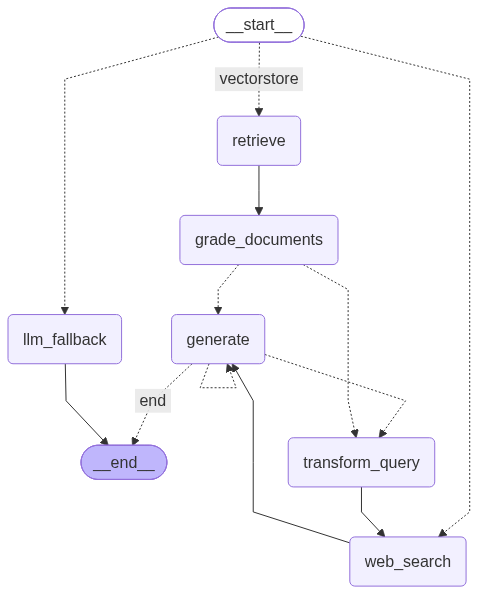

In [5]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"(Could not render PNG: {type(e).__name__}) Mermaid source:\n")
    print(app.get_graph().draw_mermaid())

## 6. Run it

In [12]:
def run(question: str) -> str:
    print("\n" + "=" * 70)
    print(f"Q: {question}")
    print("=" * 70)

    final = {}
    for step in app.stream({"question": question}):
        for node, update in step.items():
            print(f"[node] {node}")
            final.update(update)

    answer = final.get("generation", "(no answer)")
    print(f"\nA: {answer}")
    return answer

**Demo: one question per route.**

In [13]:
demo_questions = [
    "What are the types of agent memory?",        # -> vectorstore
    "Who won the most recent Formula 1 race?",    # -> web_search
    "Hi there! How are you doing?",               # -> llm_fallback
]

for q in demo_questions:
    run(q)


Q: What are the types of agent memory?
---ROUTE: vectorstore---
[node] retrieve
   kept 4/4 documents
[node] grade_documents
---GROUNDED + ANSWERS QUESTION---
[node] generate

A: The types of agent memory include **short-term memory**, which is utilized for in-context learning, and **long-term memory**, which allows agents to retain and recall information over extended periods, often through an external vector store. Additionally, there is a **memory stream**, a long-term memory module that records agents' experiences in natural language, and a **retrieval model** that surfaces relevant context based on recency, importance, and relevance.

Q: Who won the most recent Formula 1 race?
---ROUTE: web_search---
[node] web_search
---GROUNDED BUT DOESN'T ANSWER -> rewrite + web search---
[node] generate
   rewritten query: Who won the most recent Formula 1 Grand Prix as of [current date]?
[node] transform_query
[node] web_search
---GROUNDED + ANSWERS QUESTION---
[node] generate

A: The most r

**Try your own question:**

In [16]:
run("How does chain-of-thought prompting work?")


Q: How does chain-of-thought prompting work?
---ROUTE: vectorstore---
[node] retrieve
   kept 3/4 documents
[node] grade_documents
---GROUNDED + ANSWERS QUESTION---
[node] generate

A: Chain-of-thought (CoT) prompting generates a sequence of short sentences to describe reasoning logics step by step, leading to the final answer. It works by decomposing complex tasks into smaller, simpler steps, allowing the model to utilize more test-time computation and provide an interpretation of its thinking process. This method is particularly beneficial for complicated reasoning tasks and when using large models with more than 50B parameters.


'Chain-of-thought (CoT) prompting generates a sequence of short sentences to describe reasoning logics step by step, leading to the final answer. It works by decomposing complex tasks into smaller, simpler steps, allowing the model to utilize more test-time computation and provide an interpretation of its thinking process. This method is particularly beneficial for complicated reasoning tasks and when using large models with more than 50B parameters.'

## Notes
- Default chat model is `command-r-plus`; set `COHERE_MODEL` if your account uses a different one.
- To index your own content: edit `URLS`, update the router prompt to describe it, and set `REBUILD = True`.
- If you change `EMBEDDING_MODEL`, also set `REBUILD = True` (vectors from different models are incompatible).
- If you hit `Could not import sentence_transformers`, you installed into a different Python than the kernel's. Use `%pip` in a notebook cell and restart the kernel.